# Auditing a CV screener for gender bias

A guided tour of the audit, in the order of the report. Every number is read from `results/` when
the notebook runs. It loads no model and runs on a CPU. `docs/results.md` has the same story with
more detail.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
RESULTS = ROOT / "results"
PER = 100  # shares are told as "of every 100"
HOUR = 3600  # seconds
FASHION = {"model": "fashion model"}  # the job `model`; "model" alone means the AI model


def read_json(name):
    return json.loads((RESULTS / name).read_text(encoding="utf-8"))


def read_csv(name):
    return pd.read_csv(RESULTS / name)


def show_figure(name):
    display(Image(filename=str(RESULTS / "figures" / name), width=520))


def say(text):
    display(Markdown(text))


def name(job):
    return FASHION.get(job, job.replace("_", " "))


def listing(items):
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]


def pct(share, digits=0):
    return f"{PER * share:.{digits}f}%"


def ci(stat, digits=2, scale=1, sign=False, unit=""):
    """`value [low, high]` of a result that has `value`, `ci_low` and `ci_high`."""
    flag = "+" if sign else ""
    value, low, high = (scale * stat[key] for key in ("value", "ci_low", "ci_high"))
    return f"{value:{flag}.{digits}f}{unit} [{low:{flag}.{digits}f}, {high:{flag}.{digits}f}]"


def md_table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    return "\n".join(lines)


alpha = read_json("gap_statistics.json")["main_model"]["alpha"]
LEVEL_NUMBER = round(PER * (1 - alpha))
LEVEL = f"{LEVEL_NUMBER}%"

In [2]:
data = read_json("data_summary.json")
bios, share = data["bios"], data["share_women_train"]
say(
    f"The model reads a short bio and decides which of {len(share)} jobs it describes. A recruiter "
    'who searches for "surgeon" gets the bios the model labels surgeon, and the rest are set '
    "aside. The question: does the model shortlist qualified women and qualified men equally? "
    "A candidate is qualified when the bio belongs to someone who really does that job."
)

The model reads a short bio and decides which of 28 jobs it describes. A recruiter who searches for "surgeon" gets the bios the model labels surgeon, and the rest are set aside. The question: does the model shortlist qualified women and qualified men equally? A candidate is qualified when the bio belongs to someone who really does that job.

## Data

The data are professional bios from Bias in Bios, each labelled with one job and a gender
inferred from its pronouns.

In [3]:
lowest, highest = min(share, key=share.get), max(share, key=share.get)
say(
    f"`scripts/prepare_data.py` draws {bios['train']:,} training, {bios['dev']:,} development and "
    f"{bios['test']:,} test bios, stratified by job and gender with a fixed seed. The models never "
    f"see the test bios while they train. Women are {pct(share[lowest])} of the training bios for "
    f"{name(lowest)} and {pct(share[highest])} for {name(highest)}. Counting how many women and "
    "men the model shortlists would only repeat this imbalance, so I compare the share of "
    "qualified women shortlisted with the share of qualified men."
)
rows = [[name(job), pct(share[job])] for job in sorted(share, key=share.get)]
say(md_table(["Job", "Women in the training bios"], rows))

`scripts/prepare_data.py` draws 60,000 training, 10,000 development and 99,069 test bios, stratified by job and gender with a fixed seed. The models never see the test bios while they train. Women are 9% of the training bios for rapper and 93% for dietitian. Counting how many women and men the model shortlists would only repeat this imbalance, so I compare the share of qualified women shortlisted with the share of qualified men.

| Job | Women in the training bios |
|---|---|
| rapper | 9% |
| dj | 14% |
| surgeon | 15% |
| software engineer | 16% |
| composer | 16% |
| comedian | 21% |
| architect | 24% |
| pastor | 24% |
| chiropractor | 26% |
| filmmaker | 33% |
| dentist | 35% |
| photographer | 36% |
| accountant | 37% |
| attorney | 38% |
| professor | 45% |
| personal trainer | 46% |
| painter | 46% |
| poet | 49% |
| physician | 49% |
| journalist | 50% |
| teacher | 60% |
| psychologist | 62% |
| interior designer | 81% |
| fashion model | 83% |
| yoga teacher | 84% |
| paralegal | 85% |
| nurse | 91% |
| dietitian | 93% |

## Models and training

I audit a baseline model and a main model. The baseline model counts words (TF-IDF) and weighs them with logistic
regression. The main model is DeBERTa-v3-small, a transformer fine-tuned on the training bios.

`uv run python scripts/train_baseline.py` fits the baseline model. `uv run python scripts/train_deberta.py` fine-tunes the main model with learning rate 3e-05, 5 epochs, batches of 32 and seed 42. The curves come from `results/training_log.csv`, written every 375 steps.

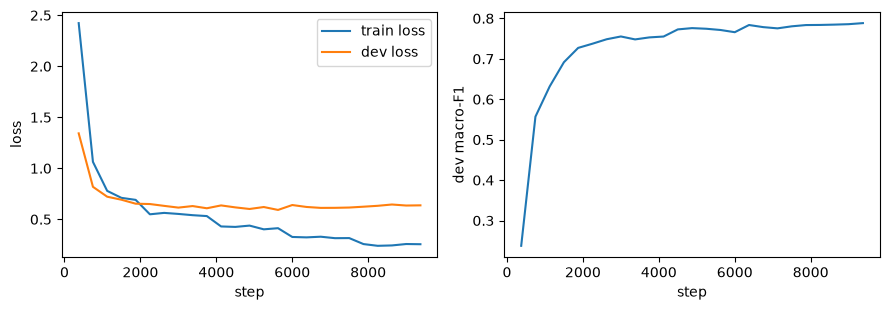

In [4]:
baseline, main = read_json("metrics_baseline.json"), read_json("metrics_deberta.json")
settings, base_settings = main["hyperparameters"], baseline["hyperparameters"]
log = read_csv("training_log.csv")
log = log[log.base_learning_rate == settings["learning_rate"]]
say(
    "`uv run python scripts/train_baseline.py` fits the baseline model. "
    "`uv run python scripts/train_deberta.py` fine-tunes the main model with learning rate "
    f"{settings['learning_rate']:g}, {settings['epochs']} epochs, batches of "
    f"{settings['effective_batch_size']} and seed {settings['seed']}. The curves come from "
    f"`results/training_log.csv`, written every {settings['evaluation_every_steps']} steps."
)
fig, (loss, f1) = plt.subplots(1, 2, figsize=(9, 3.2))
loss.plot(log.step, log.train_loss, label="train loss")
loss.plot(log.step, log.dev_loss, label="dev loss")
loss.set(xlabel="step", ylabel="loss")
loss.legend()
f1.plot(log.step, log.dev_macro_f1)
f1.set(xlabel="step", ylabel="dev macro-F1")
fig.tight_layout()
plt.show()

In [5]:
dev_main = next(
    run["best_dev_macro_f1"]
    for run in main["runs"]
    if run["learning_rate"] == settings["learning_rate"]
)
dev_base = next(
    row["dev_macro_f1"]
    for row in baseline["dev_grid"]
    if (row["C"], row["min_df"]) == (base_settings["C"], base_settings["min_df"])
)
test_main = main["test"]["macro_f1"]["value"]
rows = [
    [
        label,
        f"{m['overfitting_check']['train_macro_f1']:.3f}",
        f"{dev:.3f}",
        f"{m['test']['macro_f1']['value']:.3f}",
    ]
    for label, m, dev in (("Baseline model", baseline, dev_base), ("Main model", main, dev_main))
]
best = log.loc[log.dev_loss.idxmin()]
assert log.dev_macro_f1.iloc[-1] == log.dev_macro_f1.max() and log.dev_loss.iloc[-1] > best.dev_loss
say(md_table(["Model", "Train macro-F1", "Dev macro-F1", "Test macro-F1"], rows))
say(
    "Both models score higher on the bios they trained on, as expected. For the main model, dev "
    "macro-F1 keeps rising up to the last step, and the dev and test scores agree "
    f"({dev_main:.3f} and {test_main:.3f}). The dev loss rises slightly "
    f"after epoch {int(best.epoch)}, because the model grows more confident, including in its "
    "mistakes, while its decisions keep improving."
)

| Model | Train macro-F1 | Dev macro-F1 | Test macro-F1 |
|---|---|---|---|
| Baseline model | 0.999 | 0.729 | 0.728 |
| Main model | 0.929 | 0.788 | 0.783 |

Both models score higher on the bios they trained on, as expected. For the main model, dev macro-F1 keeps rising up to the last step, and the dev and test scores agree (0.788 and 0.783). The dev loss rises slightly after epoch 3, because the model grows more confident, including in its mistakes, while its decisions keep improving.

## The bias (F1)

For each job I take the test bios of people who really do it and count the share of women and the
share of men the model shortlists. The gap is women minus men: above zero the model favours women,
below zero it favours men. F1 plots it for every job against the share of women in the job.

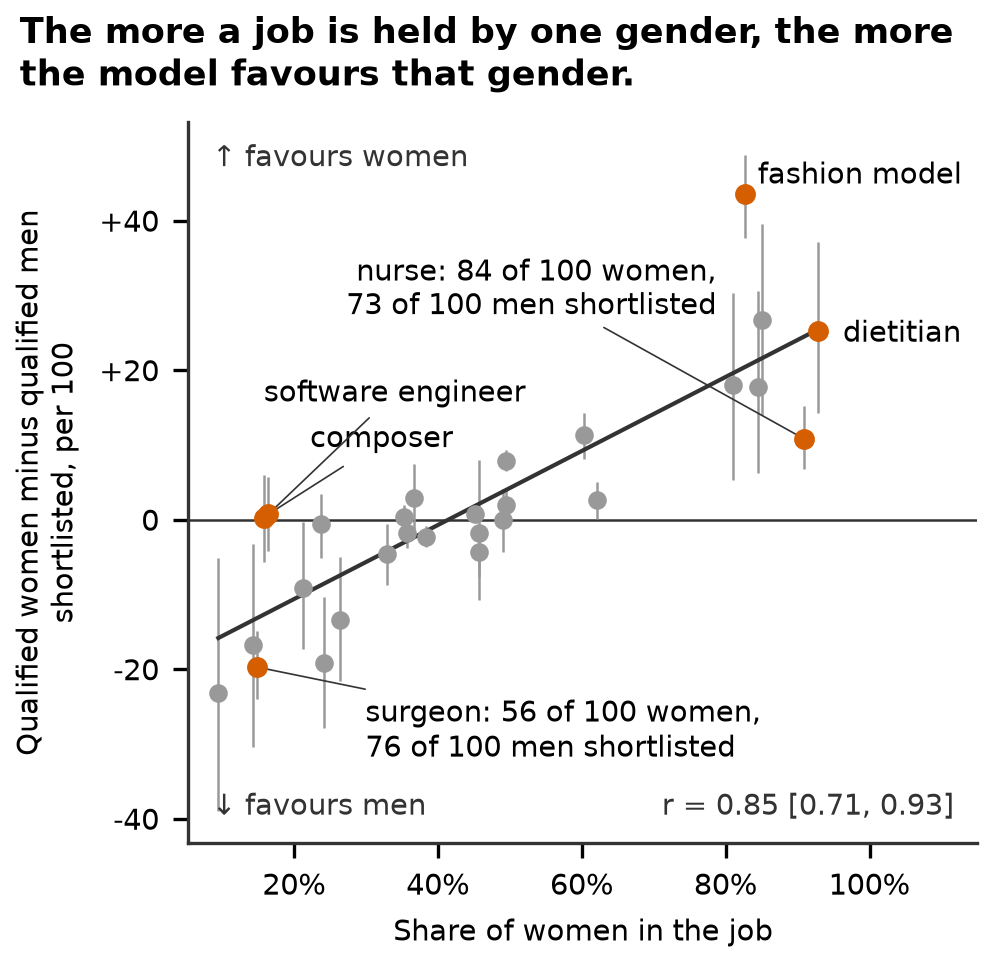

In [6]:
show_figure("f1_gap_vs_share.png")

In [7]:
stats = read_json("gap_statistics.json")["main_model"]
shuffled, pearson = stats["rms_tpr_gap"], stats["pearson"]
per_job = main["test"]["per_occupation"]
compare = main["comparison_with_baseline"]["rms_tpr_gap"]
assert compare["cis_overlap"] and pearson["fisher_ci_low"] > 0 and shuffled["p_value"] < alpha


def shortlisted(job):
    rates = per_job[job]
    return (
        f"{PER * rates['tpr_female']['value']:.0f} women and "
        f"{PER * rates['tpr_male']['value']:.0f} men"
    )


say(
    f"Of {PER} qualified surgeons the main model shortlists {shortlisted('surgeon')}. Of {PER} "
    f"qualified nurses it shortlists {shortlisted('nurse')}. Across jobs, the more women hold a "
    f"job, the more the model favours women in it: the correlation is {pearson['value']:.2f} "
    f"({LEVEL} interval {pearson['fisher_ci_low']:.2f} to {pearson['fisher_ci_high']:.2f}). "
    f"Shuffling the genders within each job gives an overall gap of {shuffled['null_mean']:.3f} on "
    f"average, against {shuffled['observed']:.3f} for the real data, so chance does not explain "
    "it."
)
say(
    f"The overall gap is {ci(main['test']['rms_tpr_gap'], 3)} for the main model and "
    f"{ci(baseline['test']['rms_tpr_gap'], 3)} for the baseline model. The intervals overlap, so "
    "the data does not show that the more accurate model is fairer. "
    "`scripts/gap_statistics.py` computes these statistics and `scripts/figure_f1.py` draws F1."
)

Of 100 qualified surgeons the main model shortlists 56 women and 76 men. Of 100 qualified nurses it shortlists 84 women and 73 men. Across jobs, the more women hold a job, the more the model favours women in it: the correlation is 0.85 (95% interval 0.71 to 0.93). Shuffling the genders within each job gives an overall gap of 0.036 on average, against 0.148 for the real data, so chance does not explain it.

The overall gap is 0.148 [0.134, 0.172] for the main model and 0.167 [0.151, 0.190] for the baseline model. The intervals overlap, so the data does not show that the more accurate model is fairer. `scripts/gap_statistics.py` computes these statistics and `scripts/figure_f1.py` draws F1.

## Global explanation: which words make the gap (F3)

A Shapley value splits the score of a bio among its words: each word gets what it adds to or takes
from the score. The score is how strongly the model leans towards a job, in score points (the
log-odds). Adding the values over many bios shows which words make the gap between women's and
men's scores.

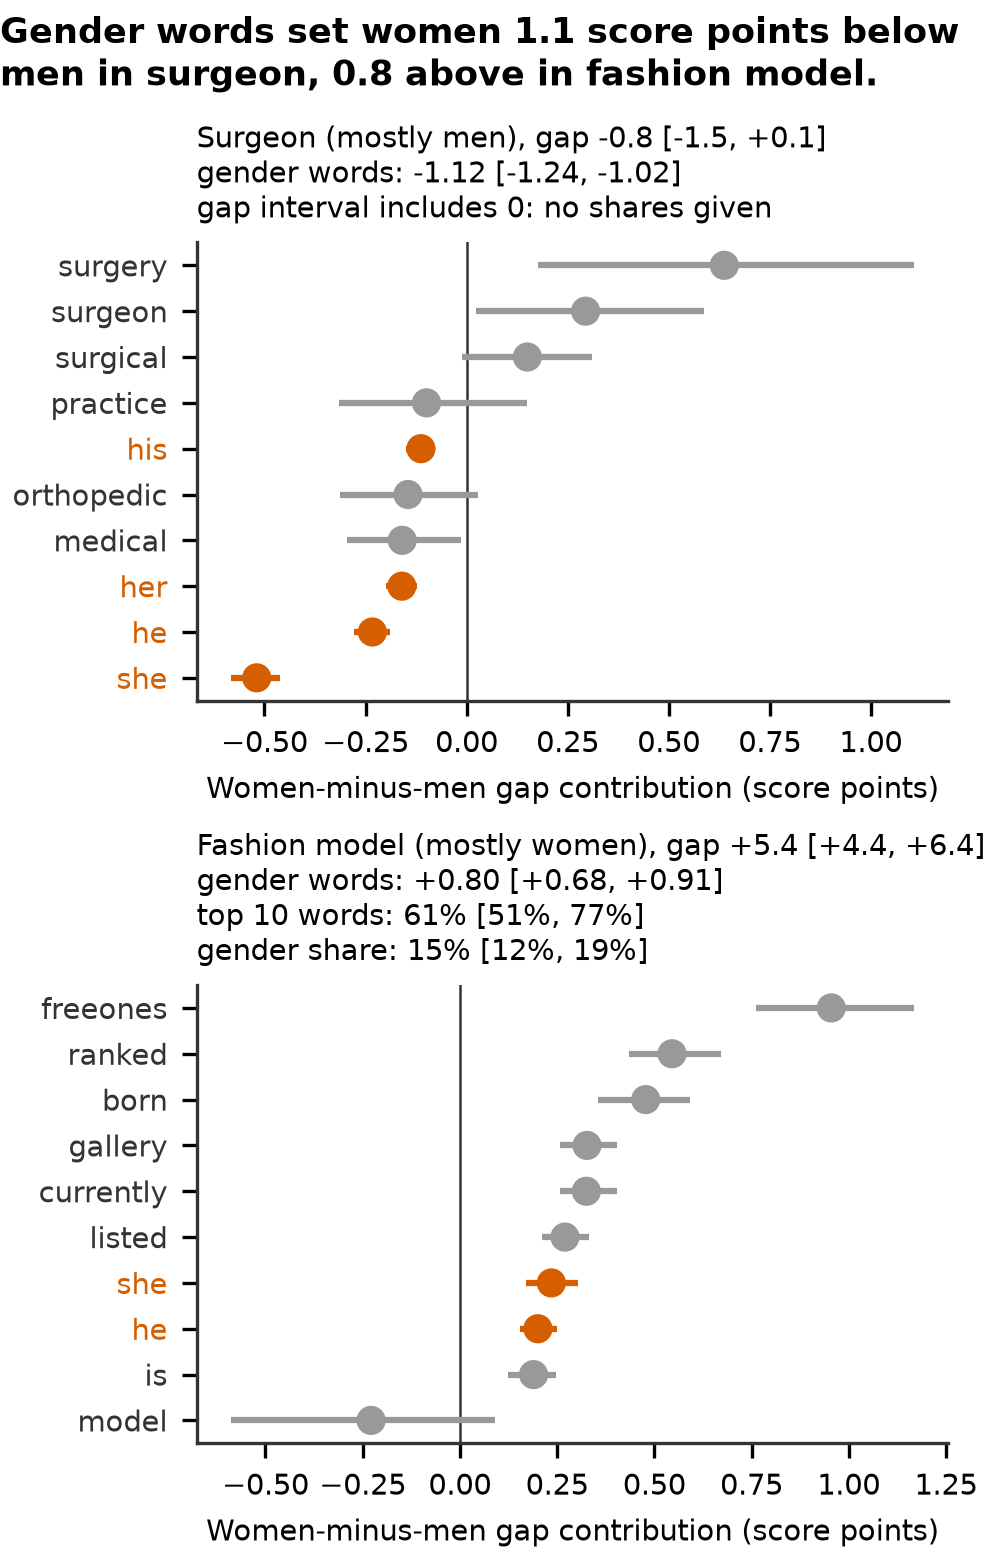

In [8]:
show_figure("f3_gap_words.png")

In [9]:
explained = read_json("gap_explained.json")
main_gaps = explained["screeners"]["deberta"]
panels = read_json("f3_panels.json")["picked"]
decomposition = read_csv("gap_decomposition.csv")
under, over = panels["male_dominated"], panels["female_dominated"]
words_under, words_over = main_gaps[under]["gendered_sum"], main_gaps[over]["gendered_sum"]
top_word = main_gaps[over]["top_words"][0]
row = decomposition[
    (decomposition.screener == "deberta")
    & (decomposition.occupation == over)
    & (decomposition.word == top_word)
].iloc[0]
in_women = round(row.freq_female * main_gaps[over]["n_female"])
in_men = round(row.freq_male * main_gaps[over]["n_male"])
assert words_under["ci_high"] < 0 < words_over["ci_low"] and in_men == 0
say(
    f"In {name(under)} bios, the gender words alone put women's scores "
    f"{abs(words_under['value']):.2f} score points below men's ({LEVEL} interval "
    f"{abs(words_under['ci_high']):.2f} to {abs(words_under['ci_low']):.2f}). In {name(over)} "
    f"bios they push women's scores up by {words_over['value']:+.2f}. The strongest single word "
    f"there is `{top_word}`, the name of a website that lists adult performers: it appears in "
    f"{in_women} of the {main_gaps[over]['n_female']} women's bios and in {in_men} of the "
    f"{main_gaps[over]['n_male']} men's. It stands in for gender without being a gender word. "
    "The split says how the gap is made up, not what would happen if a word were edited. "
    "`scripts/shapley_run.py` computes the values, `scripts/gap_decomposition.py` splits the gap "
    "and `scripts/figure_f3.py` draws F3."
)

In surgeon bios, the gender words alone put women's scores 1.12 score points below men's (95% interval 1.02 to 1.24). In fashion model bios they push women's scores up by +0.80. The strongest single word there is `freeones`, the name of a website that lists adult performers: it appears in 54 of the 150 women's bios and in 0 of the 150 men's. It stands in for gender without being a gender word. The split says how the gap is made up, not what would happen if a word were edited. `scripts/shapley_run.py` computes the values, `scripts/gap_decomposition.py` splits the gap and `scripts/figure_f3.py` draws F3.

## Local explanation: single decisions (F2)

The same values show why the model got one bio wrong. F2 picks a woman and a man whose bios the
main model labelled with the wrong job, by a rule fixed before I looked.

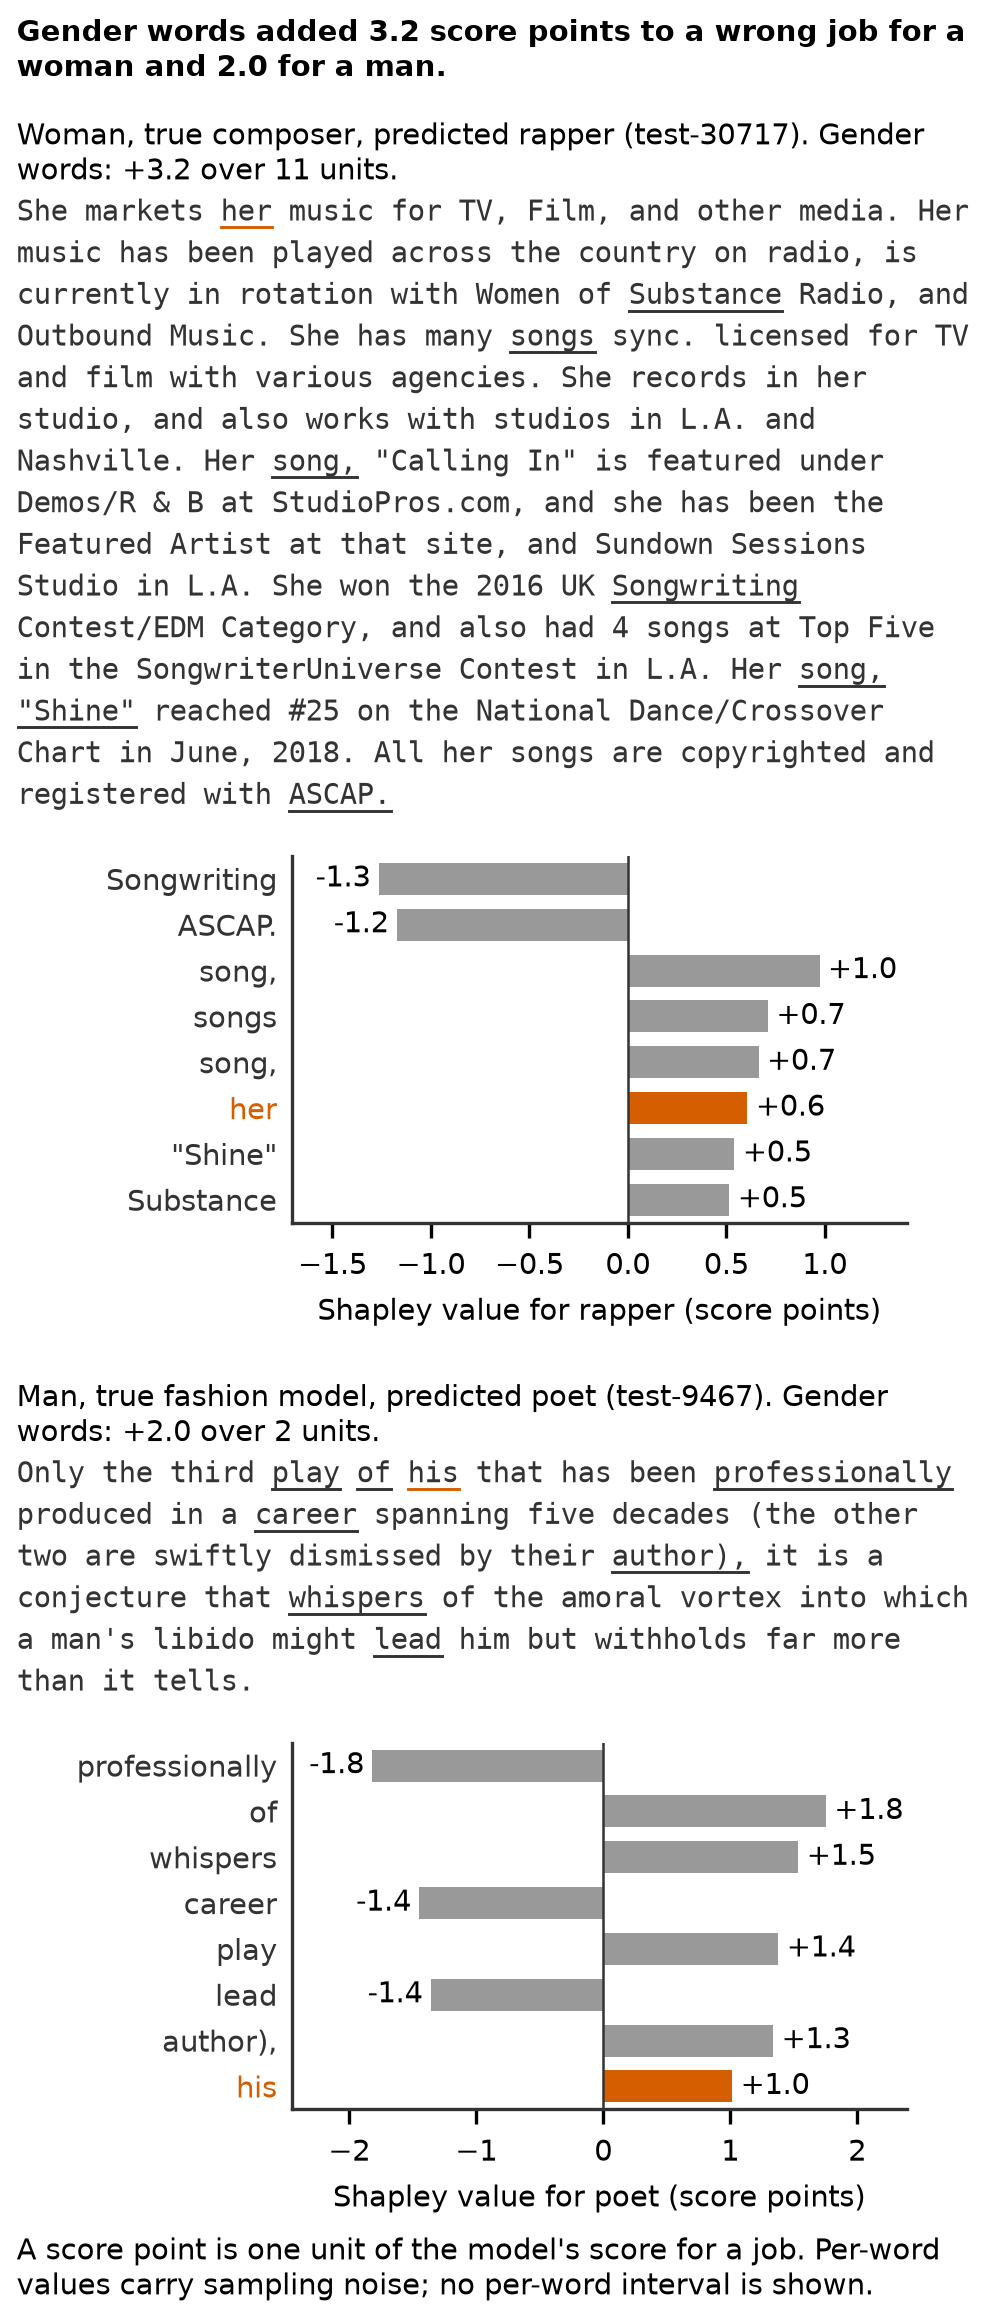

The woman is a composer labelled a rapper: her gender words add +3.2 score points to that job. The man is a fashion model labelled a poet: his gender words add +2.0. In each group they are the most extreme of 114 and 154 wrong decisions, chosen to illustrate, not typical cases. `scripts/figure_f2.py` picks them and draws F2.

In [10]:
show_figure("f2_shapley_cases.png")
cases = read_json("f2_cases.json")
woman, man = cases["women_in_male_dominated"], cases["men_in_female_dominated"]
say(
    f"The woman is a {name(woman['pick']['true'])} labelled a {name(woman['pick']['predicted'])}: "
    f"her gender words add {woman['pick']['gendered_push']:+.1f} score points to that job. The "
    f"man is a {name(man['pick']['true'])} labelled a {name(man['pick']['predicted'])}: his gender "
    f"words add {man['pick']['gendered_push']:+.1f}. In each group they are the most extreme of "
    f"{woman['n_wrong']} and {man['n_wrong']} wrong decisions, chosen to illustrate, not typical "
    "cases. `scripts/figure_f2.py` picks them and draws F2."
)

## Checking the explanations (F4, F5)

F4 swaps the gender words of a bio, he and she, his and hers, Mr and Ms, and asks
whether the decision changes. Any edit can flip a borderline decision, so I also delete the same
words and compare. F5 asks whether the words with high Shapley values matter to the model, and
whether their ranking stays the same when I compute it another way.

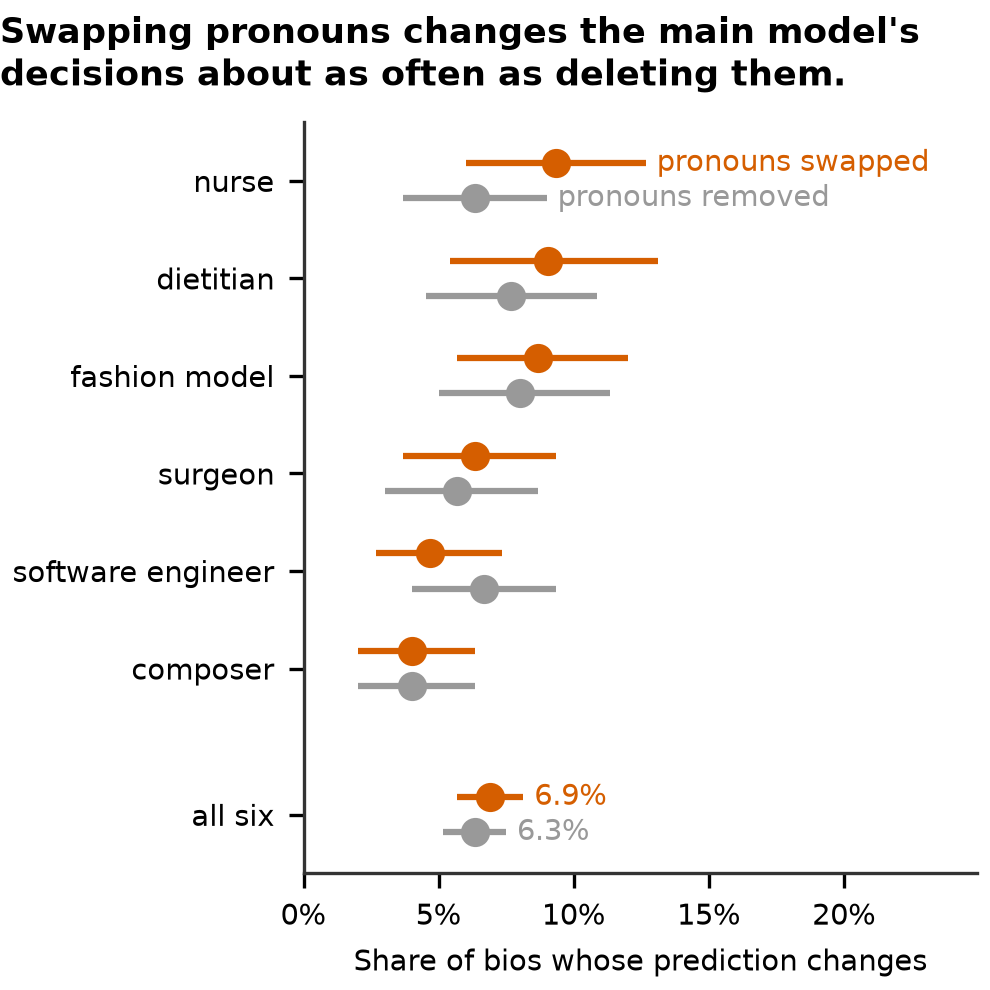

Over the 1,721 showcase bios, swapping changes 6.9% [5.7, 8.1] of the main model's decisions and deleting changes 6.3% [5.2, 7.5]. The intervals overlap, so most flips come from editing the text, and I find no extra reaction to gender itself. The baseline model reacts more to the swap (13.5%) than to the deletion (8.8%): it reads pronouns as evidence for a job. `scripts/counterfactual_gender.py` runs the test and `scripts/figure_f4.py` draws F4.

In [11]:
show_figure("f4_flip_rates.png")
flips = read_csv("counterfactual_gender.csv")


def flip(screener, condition):
    row = flips[
        (flips.screener == screener)
        & (flips.occupation == "pooled")
        & (flips.condition == condition)
        & (flips.subset == "all")
    ].iloc[0]
    return {
        "value": row.flip_rate,
        "ci_low": row.flip_rate_ci_low,
        "ci_high": row.flip_rate_ci_high,
    }


main_swap, main_delete = flip("deberta", "swap"), flip("deberta", "removal")
assert main_swap["ci_low"] <= main_delete["ci_high"]
assert main_delete["ci_low"] <= main_swap["ci_high"]
assert flip("baseline", "swap")["ci_low"] > flip("baseline", "removal")["ci_high"]
say(
    f"Over the {bios['showcase_subset']:,} showcase bios, swapping changes "
    f"{ci(main_swap, 1, PER, unit='%')} of the main model's decisions and deleting changes "
    f"{ci(main_delete, 1, PER, unit='%')}. The intervals overlap, so most flips come from editing "
    "the text, and I find no extra reaction to gender itself. The baseline model reacts more to "
    f"the swap ({pct(flip('baseline', 'swap')['value'], 1)}) than to the deletion "
    f"({pct(flip('baseline', 'removal')['value'], 1)}): it reads pronouns as evidence for a job. "
    "`scripts/counterfactual_gender.py` runs the test and `scripts/figure_f4.py` draws F4."
)

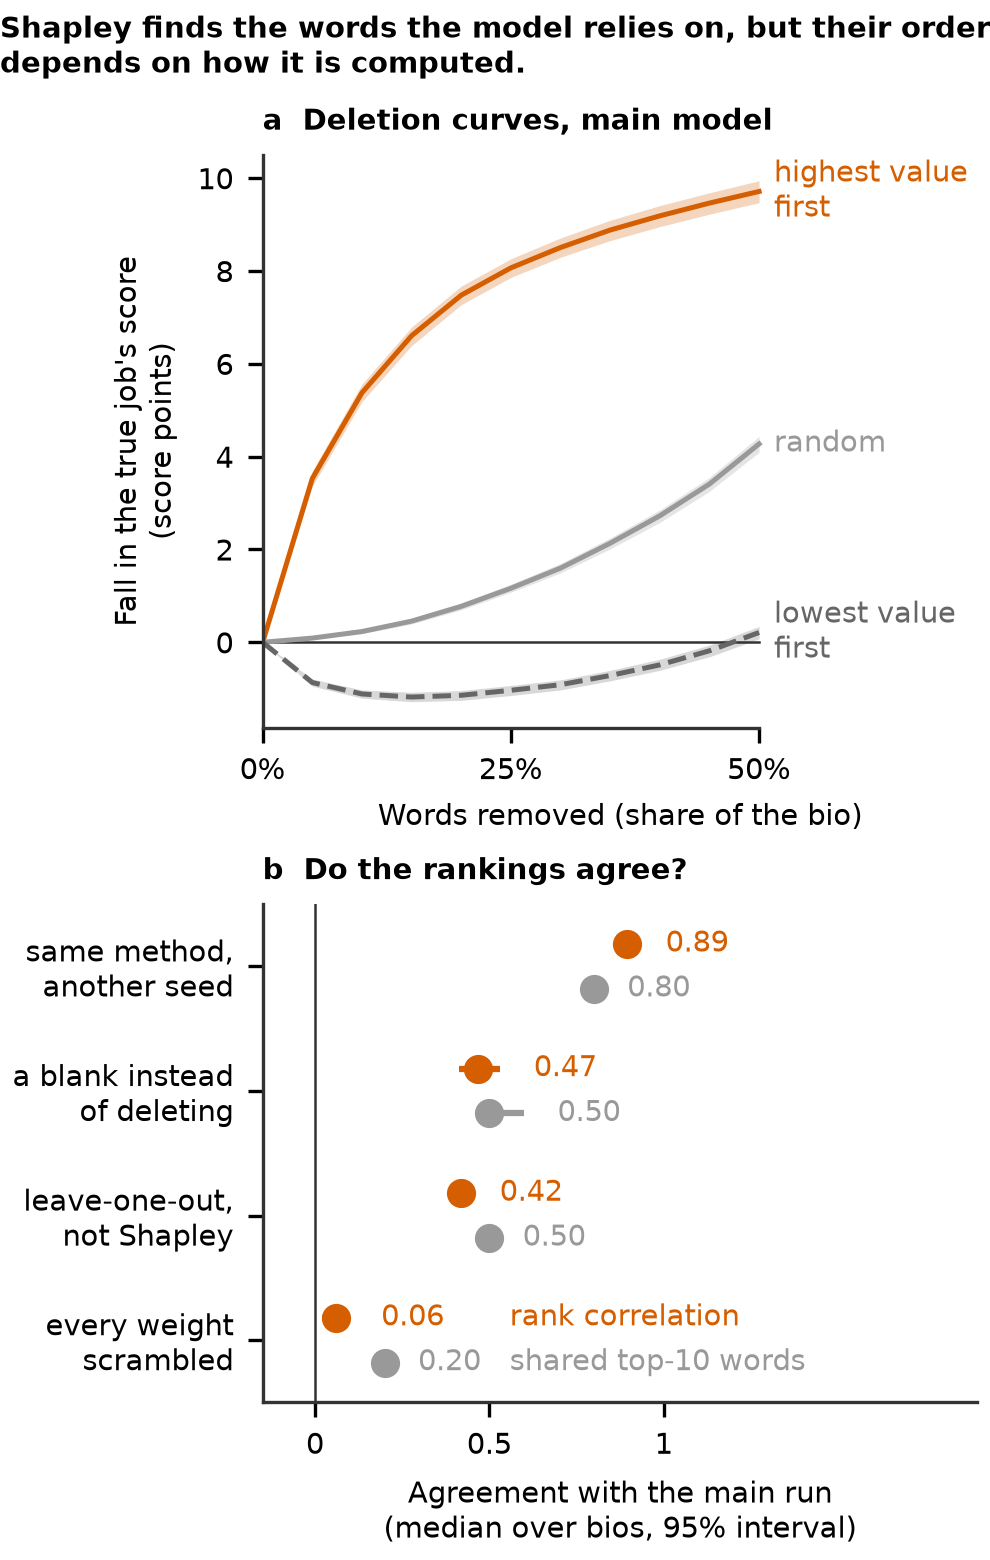

I remove a bio's words step by step, highest Shapley value first, at random, or lowest value first. Averaged over the steps, the main model's score for the true job falls by 7.0 score points when the top words go first, 1.5 at random, and it rises by 0.7 when the least useful words go first. The words Shapley ranks highest do matter to the model. `scripts/deletion_curves.py` runs this check.

In [12]:
show_figure("f5_explanation_checks.png")
areas = read_json("deletion_areas.json")
drops = areas["screeners"]["deberta"]["logodds_drop"]["area"]
assert drops["morf"]["ci_low"] > drops["random"]["ci_high"] and drops["lerf"]["value"] < 0
say(
    "I remove a bio's words step by step, highest Shapley value first, at random, or lowest value "
    "first. Averaged over the steps, the main model's score for the true job falls by "
    f"{drops['morf']['value']:.1f} score points when the top words go first, "
    f"{drops['random']['value']:.1f} at random, and it rises by {-drops['lerf']['value']:.1f} when the least "
    "useful words go first. The words Shapley ranks highest do matter to the model. "
    "`scripts/deletion_curves.py` runs this check."
)

In [13]:
stability = read_json("stability.json")
checks = {**stability["checks"], "randomisation": stability["randomisation"]}
labels = {
    "seed": "Same method, another seed",
    "removal": "`[UNK]` instead of deleting the word",
    "method": "Leave-one-out instead of Shapley",
    "randomisation": "Every weight of the model scrambled",
}
top = stability["settings"]["top"]
rho = {key: checks[key]["spearman"] for key in labels}
assert rho["randomisation"]["median_ci"][1] < rho["seed"]["median_ci"][0]
rows = [
    [
        labels[key],
        f"{checks[key]['n_bios']:,}",
        f"{rho[key]['median']:.2f} [{rho[key]['median_ci'][0]:.2f}, {rho[key]['median_ci'][1]:.2f}]",
        f"{round(top * checks[key]['top10_overlap']['median'])} of {top}",
    ]
    for key in labels
]
say(
    "Next I compare the ranking of the main run with other ways of computing it, bio by bio: the "
    "rank correlation over all the words of a bio (the maximum means the same order) and how many "
    f"of the {top} strongest words both rankings share. The table gives the median over bios. "
    "Another seed gives almost the same ranking. A different method agrees much less, so the "
    "order of the words in one bio is an indication, and I trust the totals over many bios. "
    "The scrambled model is a control: its words no longer follow the trained model's, so the "
    "explanations follow what the model learned. `scripts/stability_runs.py` and "
    "`scripts/stability.py` compute the table and `scripts/figure_f5.py` draws F5."
)
say(md_table(["Compared with the main run", "Bios", "Rank correlation", "Top words shared"], rows))

Next I compare the ranking of the main run with other ways of computing it, bio by bio: the rank correlation over all the words of a bio (the maximum means the same order) and how many of the 10 strongest words both rankings share. The table gives the median over bios. Another seed gives almost the same ranking. A different method agrees much less, so the order of the words in one bio is an indication, and I trust the totals over many bios. The scrambled model is a control: its words no longer follow the trained model's, so the explanations follow what the model learned. `scripts/stability_runs.py` and `scripts/stability.py` compute the table and `scripts/figure_f5.py` draws F5.

| Compared with the main run | Bios | Rank correlation | Top words shared |
|---|---|---|---|
| Same method, another seed | 100 | 0.89 [0.88, 0.91] | 8 of 10 |
| `[UNK]` instead of deleting the word | 100 | 0.47 [0.41, 0.53] | 5 of 10 |
| Leave-one-out instead of Shapley | 1,721 | 0.42 [0.40, 0.43] | 5 of 10 |
| Every weight of the model scrambled | 100 | 0.06 [0.02, 0.09] | 2 of 10 |

## Inside the model (F6)

Removing the pronouns is the usual first fix, so is gender gone afterwards? A linear probe is a
simple classifier that guesses gender from the model's internal state for a bio at one layer.
Patching then asks whether that state matters: it copies the internal state of the original bio
into the run on the swapped bio and measures how much of the original score comes back.

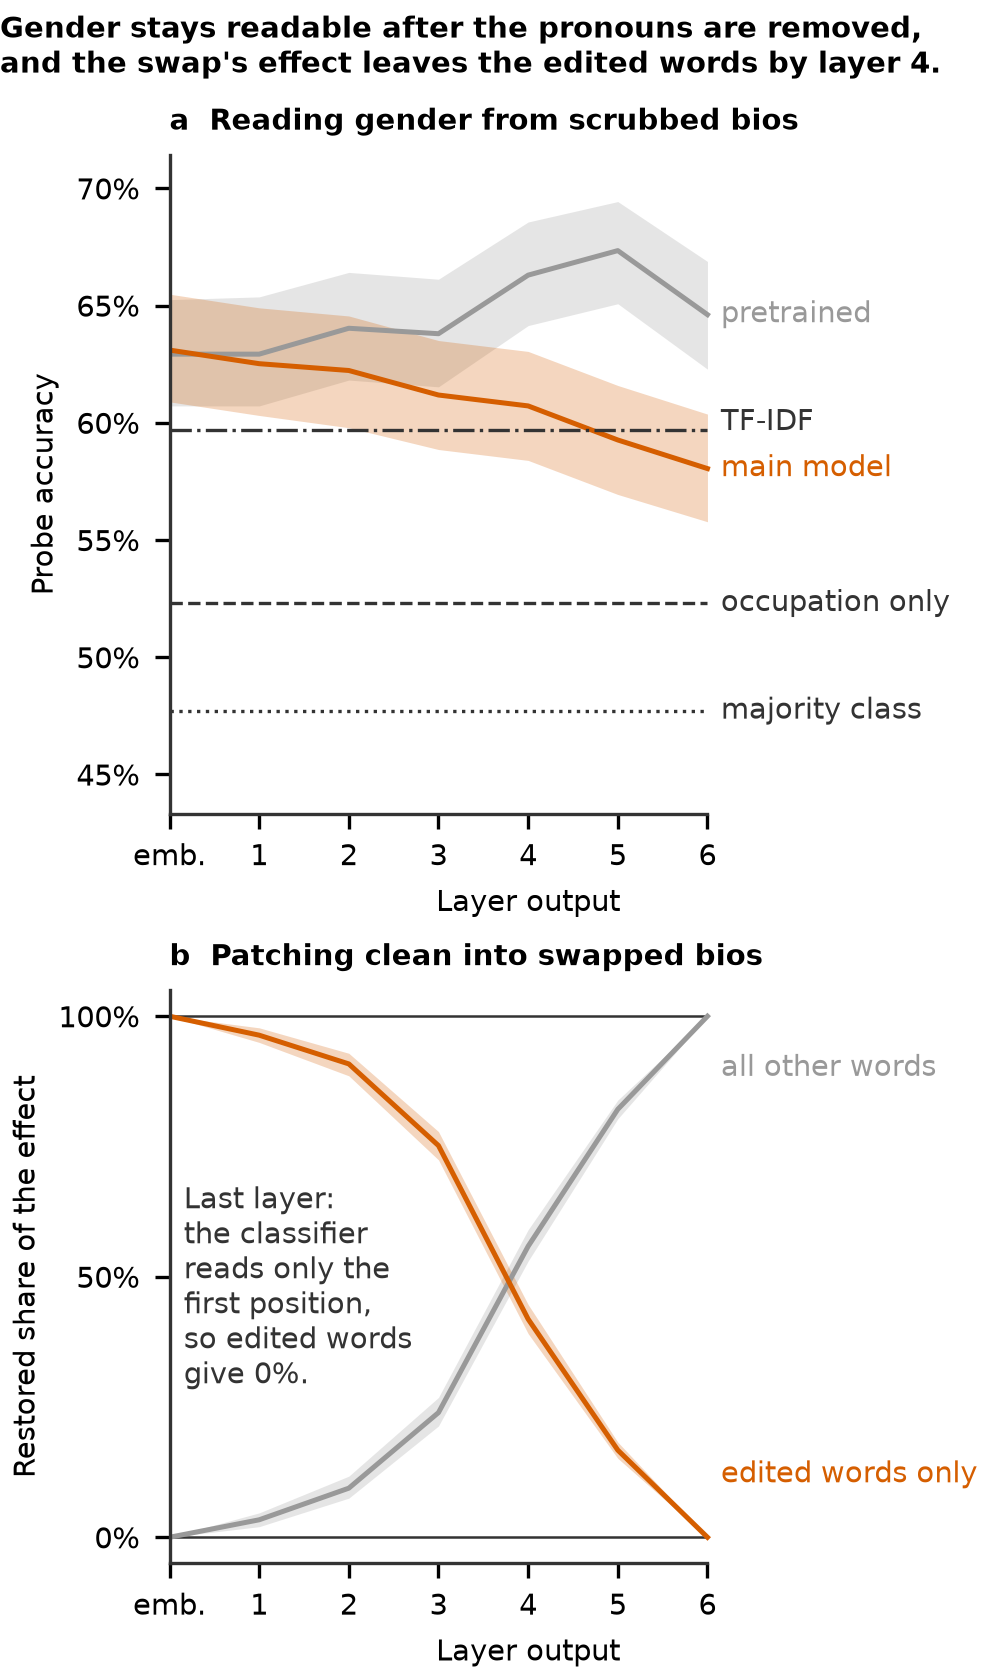

On bios without pronouns or titles, the probes still guess gender from 58% to 63% of the time on the main model, across its layers. The job alone gives 52.3% [50.0, 54.6], and word counts (TF-IDF) on the same text give 59.7% [57.2, 62.0]. Gender is still readable after scrubbing, partly in the words themselves. A probe that reads gender does not show that the model uses it. `scripts/probing.py` fits the probes.

In [14]:
show_figure("f6_probing_patching.png")
probing = read_csv("probing.csv")
probing = probing[probing.subset == "all"]
tuned = probing[probing.model == "deberta"]
reference = probing[probing.model.isin(["occupation_only", "tfidf"])].set_index("model")


def accuracy(row):
    stat = {"value": row.accuracy, "ci_low": row.ci_low, "ci_high": row.ci_high}
    return ci(stat, 1, PER, unit="%")


assert tuned.ci_low.min() > reference.loc["occupation_only", "ci_high"]
say(
    "On bios without pronouns or titles, the probes still guess gender from "
    f"{pct(tuned.accuracy.min())} to {pct(tuned.accuracy.max())} of the time on the main model, "
    f"across its layers. The job alone gives {accuracy(reference.loc['occupation_only'])}, and "
    f"word counts (TF-IDF) on the same text give {accuracy(reference.loc['tfidf'])}. Gender "
    "is still readable after scrubbing, partly in the words themselves. A probe that reads gender "
    "does not show that the model uses it. `scripts/probing.py` fits the probes."
)

In [15]:
patching_run = read_json("patching.json")
patching = read_csv("patching.csv")
patched = {
    which: patching[patching.position_set == which].set_index("layer")["mean"]
    for which in ("differing", "others")
}
handover = min(
    layer for layer in patched["others"].index if patched["others"][layer] > patched["differing"][layer]
)
say(
    f"For patching I use the {patching_run['n_patched']} swapped bios the swap moves most. At "
    f"layer {handover - 1} the states of the swapped words alone bring back "
    f"{pct(patched['differing'][handover - 1])} of the effect. From layer {handover} on, the other "
    "words of the bio bring back more than the swapped words do: the effect starts in the "
    "swapped words and spreads into the rest of the bio within a few layers. This shows the "
    "swapped words are enough to restore the effect, not that they are needed. "
    "`scripts/patching.py` runs it and `scripts/figure_f6.py` draws F6."
)

For patching I use the 168 swapped bios the swap moves most. At layer 3 the states of the swapped words alone bring back 75% of the effect. From layer 4 on, the other words of the bio bring back more than the swapped words do: the effect starts in the swapped words and spreads into the rest of the bio within a few layers. This shows the swapped words are enough to restore the effect, not that they are needed. `scripts/patching.py` runs it and `scripts/figure_f6.py` draws F6.

## Mitigation (F7)

I try fixes and measure what each does to the gap and to macro-F1. The first retrains the
main model on bios without pronouns and titles. The second deletes proxy words: words that are
not pronouns but that women's and men's bios use at different rates.

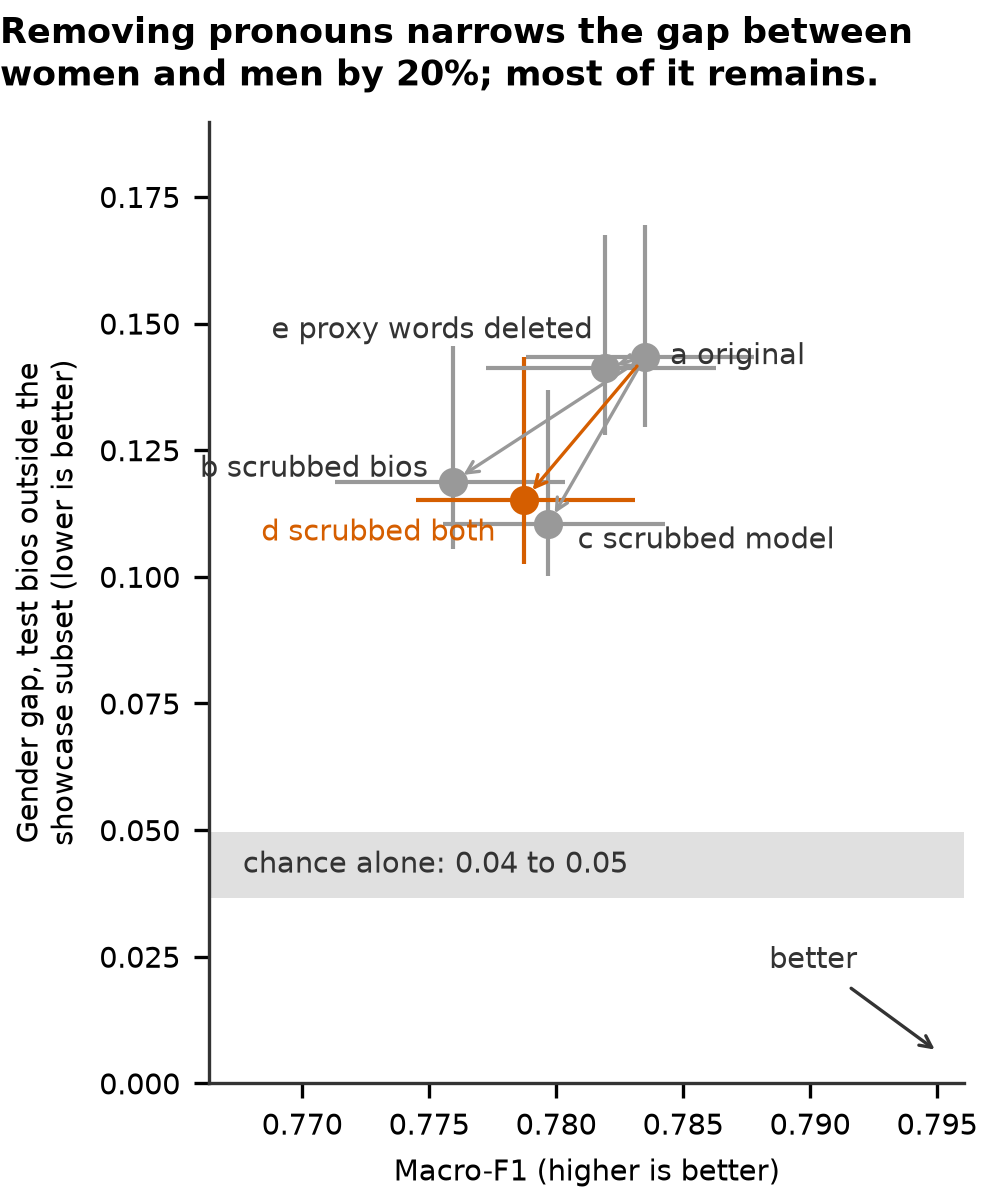

Scrubbing narrows the gap from 0.143 to 0.115, at a cost of 0.5 points of macro-F1. It leaves the model unequal: shuffled genders give 0.037 on average, and every condition stays above that. Deleting the proxy words (born, currently, freeones, gallery, ranked and registered) leaves the gap where it was. Each model has one training run, so the difference between the original and the scrubbed model includes run-to-run variation that I did not measure. `scripts/train_scrubbed.py`, `scripts/proxy_words.py` and `scripts/mitigation.py` produce the conditions; `scripts/figure_f7.py` draws F7.

| Condition | Macro-F1 | Gender gap |
|---|---|---|
| a. original model, raw bios | 0.784 [0.779, 0.788] | 0.143 [0.130, 0.169] |
| b. original model, scrubbed bios | 0.776 [0.771, 0.780] | 0.119 [0.105, 0.145] |
| c. scrubbed model, raw bios | 0.780 [0.776, 0.784] | 0.110 [0.100, 0.137] |
| d. scrubbed model, scrubbed bios | 0.779 [0.774, 0.783] | 0.115 [0.103, 0.143] |
| e. original model, proxy words deleted | 0.782 [0.777, 0.786] | 0.141 [0.128, 0.167] |

In [16]:
show_figure("f7_mitigation.png")
mitigation = read_json("mitigation.json")
proxy = read_json("proxy_words.json")
labels = {
    "a": "a. original model, raw bios",
    "b": "b. original model, scrubbed bios",
    "c": "c. scrubbed model, raw bios",
    "d": "d. scrubbed model, scrubbed bios",
    "e": "e. original model, proxy words deleted",
}
scored = {key: mitigation["conditions"][key]["outside_showcase"] for key in labels}
chance = scored["a"]["rms_tpr_gap"]["null"]
assert min(s["rms_tpr_gap"]["value"] for s in scored.values()) > chance["p95"]
assert scored["d"]["change_from_a"]["rms_tpr_gap"]["ci_high"] < 0
assert scored["e"]["change_from_a"]["rms_tpr_gap"]["ci_high"] > 0
rows = [
    [labels[key], ci(scored[key]["macro_f1"], 3), ci(scored[key]["rms_tpr_gap"], 3)]
    for key in labels
]
say(
    f"Scrubbing narrows the gap from {scored['a']['rms_tpr_gap']['value']:.3f} to "
    f"{scored['d']['rms_tpr_gap']['value']:.3f}, at a cost of "
    f"{-PER * scored['d']['change_from_a']['macro_f1']['value']:.1f} points of macro-F1. It leaves "
    f"the model unequal: shuffled genders give {chance['mean']:.3f} on average, and every "
    "condition stays above that. Deleting the proxy words "
    f"({listing(proxy['words'])}) leaves the gap where it was. Each model has one training "
    "run, so the difference between the original and the scrubbed model includes run-to-run "
    "variation that I did not measure. `scripts/train_scrubbed.py`, `scripts/proxy_words.py` and "
    "`scripts/mitigation.py` produce the conditions; `scripts/figure_f7.py` draws F7."
)
say(md_table(["Condition", "Macro-F1", "Gender gap"], rows))

## LLM screener (F8)

Companies now let a general-purpose LLM read a bio and decide who goes to an interview. I cannot
open such a model, so I test it from outside: the same bio goes in with different names, and I
watch whether the answer changes.

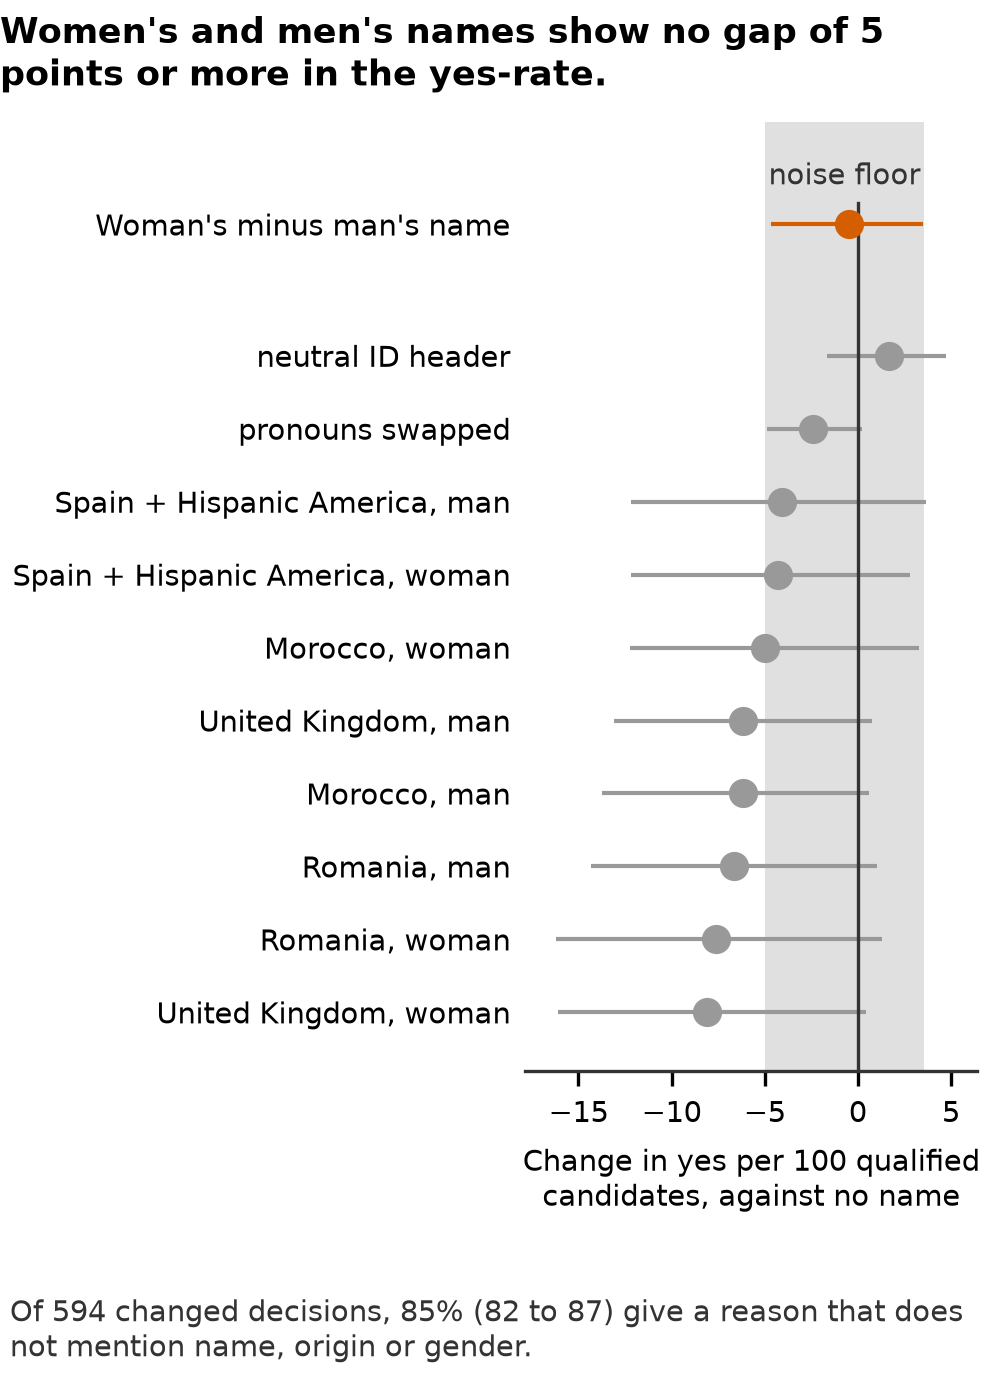

`scripts/llm_run.py` asks prism-ml/Ternary-Bonsai-2-9B-gguf (served on the laptop) for a yes or a no on a job ad and a bio: 600 profiles, 8,167 calls in 3.0 hours. Comparing qualified candidates with a woman's name and with a man's name, pooled over jobs and origin groups, the yes-rate differs by -0.5 [-4.7, +3.5] points. The interval rules out gaps larger than 4.7 points, not smaller ones. What does move the answer is having a name at all, -6.0 [-10.1, -2.1] points against no name, and how the instruction is worded: 13% and 16% of the decisions change with the reworded instructions. `scripts/llm_analyse.py` writes the results and `scripts/figure_f8.py` draws F8.

In [17]:
show_figure("f8_llm_screener.png")
audit = read_json("llm_audit.json")
card, cost, profiles = audit["model_card"], audit["run_cost"], audit["profiles"]
stats, sensitivity = audit["statistics"], audit["prompt_sensitivity"]
primary, pooled = stats["primary"], stats["pooled_names_vs_none"]
assert primary["ci_low"] < 0 < primary["ci_high"] and pooled["ci_high"] < 0
widest = PER * max(abs(primary["ci_low"]), abs(primary["ci_high"]))
say(
    f"`scripts/llm_run.py` asks {card['huggingface']} (served on the laptop) for a yes or a no on "
    f"a job ad and a bio: {profiles['n_profiles']} profiles, {cost['n_calls']:,} calls in "
    f"{cost['seconds_total'] / HOUR:.1f} hours. Comparing qualified candidates with a woman's name "
    "and with a man's name, pooled over jobs and origin groups, the yes-rate differs by "
    f"{ci(primary, 1, PER, sign=True)} points. The interval rules out gaps larger than "
    f"{widest:.1f} points, not smaller ones. What does move the answer is having a name at all, "
    f"{ci(pooled, 1, PER, sign=True)} points against no name, and how the instruction is worded: "
    f"{pct(sensitivity['v2']['flip_rate_against_v1'])} and "
    f"{pct(sensitivity['v3']['flip_rate_against_v1'])} of the decisions change with the reworded "
    "instructions. `scripts/llm_analyse.py` writes the results and `scripts/figure_f8.py` draws "
    "F8."
)

## Limits

- Each model has one training run, so the scrubbed and original models differ also by run-to-run
  noise that I did not measure.
- Gender is binary and inferred from pronouns, so the swap says nothing about non-binary people.
- The deletion check puts a blank into a model trained on text without blanks, and the scrambling
  redraws all weights at once. Patching shows that states are enough, not that they are needed.
- The explanations run on a fixed subset of bios from a few jobs. The value of one word in one
  bio is an indication; the totals over many bios are the solid result.
- The LLM audit covers one small model, one prompt with rewordings and a few jobs, and a stated
  reason can differ from what the model computes.